# 01 EDA - Dataset MathE

Objetivo: describir cada variable y transformar las categóricas a numéricas (Tarea 1).

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # para poder importar src/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import cargar_datos, TARGET, DATOS_PROCESADOS

## 1. Carga y vista general

In [2]:
df = cargar_datos()
print(df.shape)
df.head()

(9546, 8)


,Student ID,Student Country,Question ID,Type of Answer,Question Level,Topic,Subtopic,Keywords
0,647,Ireland,77,0,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."
1,41,Portugal,77,1,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."
2,340,Portugal,77,1,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."
3,641,Italy,77,0,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."
4,669,Portugal,77,1,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9546 entries, 0 to 9545
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Student ID       9546 non-null   int64
 1   Student Country  9546 non-null   str  
 2   Question ID      9546 non-null   int64
 3   Type of Answer   9546 non-null   int64
 4   Question Level   9546 non-null   str  
 5   Topic            9546 non-null   str  
 6   Subtopic         9546 non-null   str  
 7   Keywords         9546 non-null   str  
dtypes: int64(3), str(5)
memory usage: 596.8 KB


In [4]:
df.isna().sum()

Student ID         0
Student Country    0
Question ID        0
Type of Answer     0
Question Level     0
Topic              0
Subtopic           0
Keywords           0
dtype: int64

In [5]:
df.nunique()

Student ID         372
Student Country      8
Question ID        833
Type of Answer       2
Question Level       2
Topic               14
Subtopic            24
Keywords           365
dtype: int64

## 2. Variable objetivo: `Type of Answer`

¿Están balanceadas las clases?

Type of Answer
0    5076
1    4470
Name: count, dtype: int64
Type of Answer
0    0.532
1    0.468
Name: proportion, dtype: float64


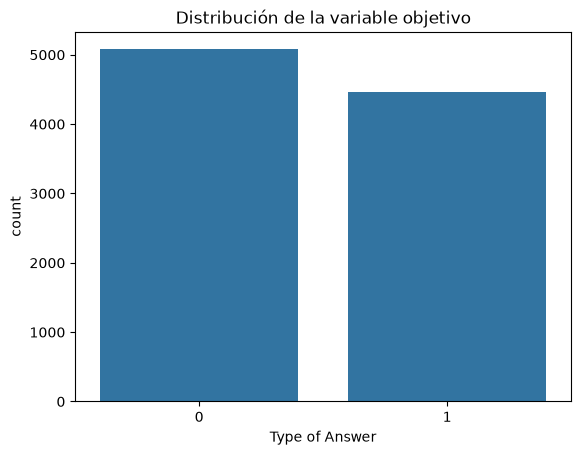

In [6]:
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(3))
sns.countplot(x=TARGET, data=df)
plt.title('Distribución de la variable objetivo')
plt.show()

**Conclusiones:**
- Las clases están prácticamente balanceadas: 5076 respuestas incorrectas (53,2 %) y 4470 correctas (46,8 %). La diferencia es de unos 6 puntos porcentuales, lejos de la "fuerte diferencia" que define un desbalance de clases.
- Por lo tanto, decidimos no aplicar técnicas de balanceo (undersampling, oversampling ni ponderación de clases).
- Línea base para evaluar los modelos: un clasificador que siempre predice "incorrecta" obtiene un *accuracy* de 0.532, por lo que un modelo útil tiene que superar claramente ese valor.

## 3. Variables categóricas

In [7]:
for col in ['Student Country', 'Question Level', 'Topic', 'Subtopic']:
    print(f'--- {col} ---')
    print(df[col].value_counts().head(15), '\n')

--- Student Country ---
Student Country
Portugal              5495
Lithuania             1443
Italy                 1358
Slovenia               755
Ireland                300
Russian Federation     107
Romania                 60
Spain                   28
Name: count, dtype: int64 

--- Question Level ---
Question Level
Basic       7844
Advanced    1702
Name: count, dtype: int64 

--- Topic ---
Topic
Linear Algebra                         5726
Fundamental Mathematics                 818
Complex Numbers                         592
Differentiation                         579
Analytic Geometry                       358
Statistics                              340
Numerical Methods                       310
Optimization                            182
Real Functions of a single variable     164
Integration                             144
Probability                             128
Differential Equations                  108
Graph Theory                             55
Set Theory              

In [8]:
# Tasa de respuestas correctas por categoría
for col in ['Student Country', 'Question Level', 'Topic', 'Subtopic']:
    tasa = df.groupby(col)[TARGET].agg(['mean', 'count']).sort_values('count', ascending=False)
    display(tasa.head(15))

,mean,count
Student Country,,
Portugal,0.453867,5495
Lithuania,0.435897,1443
Italy,0.446244,1358
Slovenia,0.687417,755
Ireland,0.460000,300
Russian Federation,0.345794,107
Romania,0.583333,60
Spain,0.428571,28


,mean,count
Question Level,,
Basic,0.461117,7844
Advanced,0.501175,1702


,mean,count
Topic,,
Linear Algebra,0.490220,5726
Fundamental Mathematics,0.465770,818
Complex Numbers,0.454392,592
Differentiation,0.341969,579
Analytic Geometry,0.488827,358
Statistics,0.479412,340
Numerical Methods,0.387097,310
Optimization,0.384615,182
Real Functions of a single variable,0.353659,164


,mean,count
Subtopic,,
Vector Spaces,0.463805,2749
Linear Transformations,0.503526,2127
Complex Numbers,0.454392,592
"Algebraic expressions, Equations, and Inequalities",0.387097,496
Linear Systems,0.561905,420
Analytic Geometry,0.488827,358
Statistics,0.479412,340
Elementary Geometry,0.586957,322
Derivatives,0.356467,317


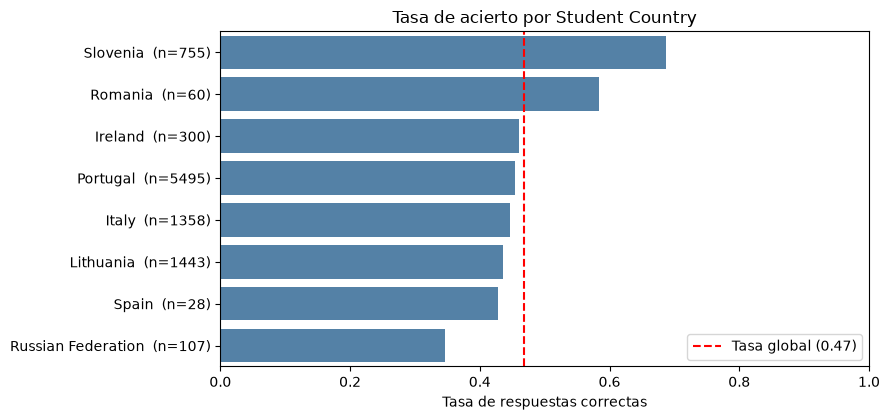

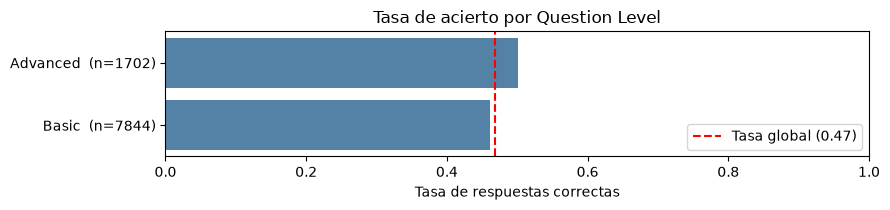

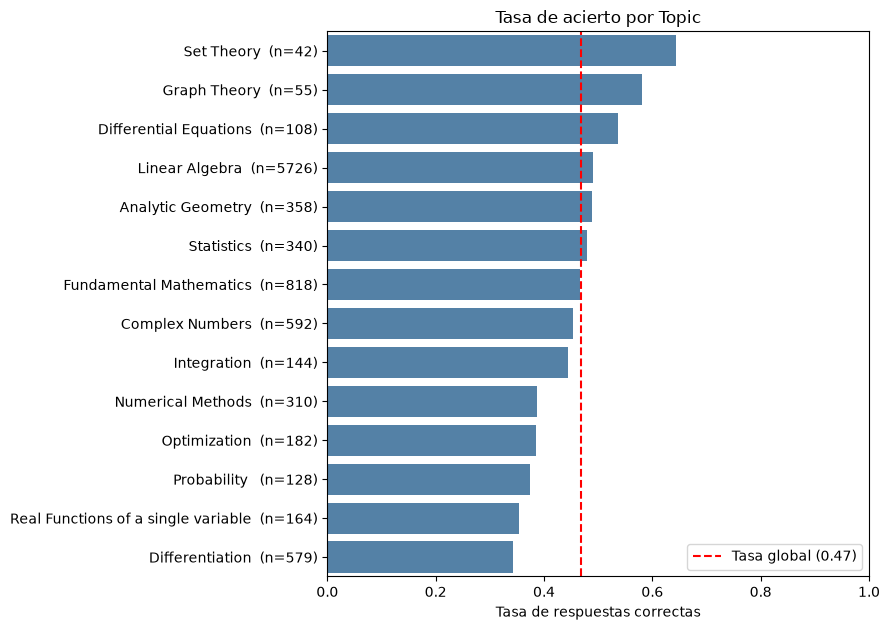

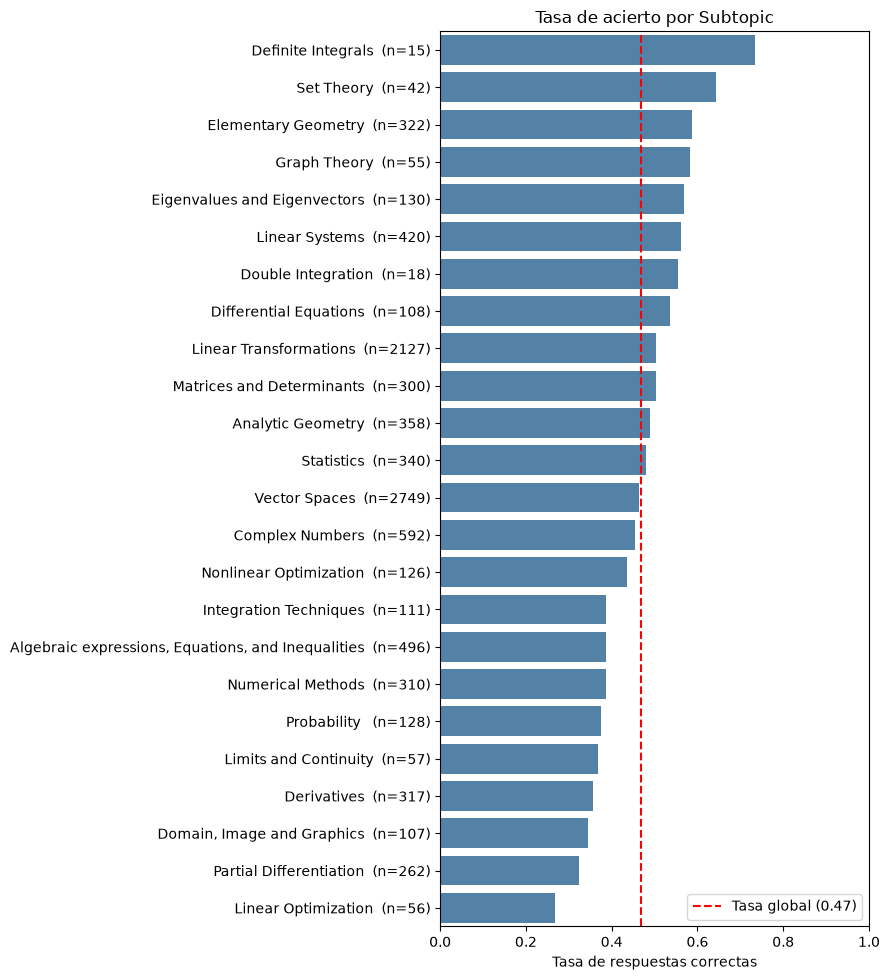

In [9]:
# Tasa de acierto por categoría (n = cantidad de respuestas de cada categoría)
tasa_global = df[TARGET].mean()

for col in ['Student Country', 'Question Level', 'Topic', 'Subtopic']:
    orden = df.groupby(col)[TARGET].mean().sort_values(ascending=False).index
    conteo = df[col].value_counts()

    fig, ax = plt.subplots(figsize=(9, 0.35 * len(orden) + 1.5))
    sns.barplot(data=df, y=col, x=TARGET, order=orden, errorbar=None,
                color='steelblue', ax=ax)
    ax.axvline(tasa_global, color='red', linestyle='--', label=f'Tasa global ({tasa_global:.2f})')
    ax.set_yticks(range(len(orden)), [f'{c}  (n={conteo[c]})' for c in orden])
    ax.set_xlim(0, 1)
    ax.set_xlabel('Tasa de respuestas correctas')
    ax.set_ylabel('')
    ax.set_title(f'Tasa de acierto por {col}')
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

### 3.1 Relaciones entre variables

Aparecen dos resultados llamativos: **Slovenia** acierta mucho más que el resto de los países, y las preguntas **Advanced** tienen una tasa de acierto *mayor* que las Basic. Se revisa si se explican por la relación con otras variables.

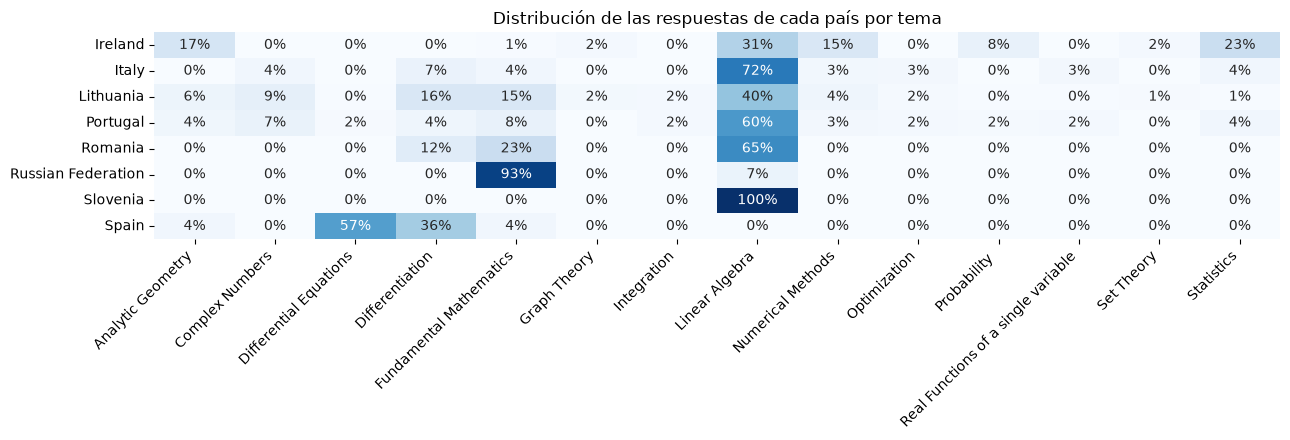

,respuestas,estudiantes,resp_estudiante_principal,tasa_acierto,% estudiante principal
Student Country,,,,,
Portugal,5495,245,221,0.45,4.02
Lithuania,1443,56,321,0.44,22.25
Italy,1358,50,125,0.45,9.20
Slovenia,755,3,727,0.69,96.29
Ireland,300,13,142,0.46,47.33
Russian Federation,107,1,107,0.35,100.00
Romania,60,3,36,0.58,60.00
Spain,28,1,28,0.43,100.00


mean  count
Student Country Subtopic                                  
Resto de países Eigenvalues and Eigenvectors  0.569    130
                Linear Systems                0.562    420
                Linear Transformations        0.465   1861
                Matrices and Determinants     0.503    300
                Vector Spaces                 0.426   2260
Slovenia        Linear Transformations        0.774    266
                Vector Spaces                 0.640    489

In [10]:
# ¿Qué temas responde cada país? (proporción de las respuestas de cada país por tema)
pais_tema = pd.crosstab(df['Student Country'], df['Topic'], normalize='index')

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(pais_tema, annot=True, fmt='.0%', cmap='Blues', cbar=False, ax=ax)
ax.set_title('Distribución de las respuestas de cada país por tema')
ax.set_xlabel('')
ax.set_ylabel('')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ¿Cuántos estudiantes hay detrás de cada país?
por_pais = df.groupby('Student Country').agg(
    respuestas=('Student ID', 'size'),
    estudiantes=('Student ID', 'nunique'),
    resp_estudiante_principal=('Student ID', lambda s: s.value_counts().max()),
    tasa_acierto=(TARGET, 'mean'),
)
por_pais['% estudiante principal'] = 100 * por_pais['resp_estudiante_principal'] / por_pais['respuestas']
display(por_pais.sort_values('respuestas', ascending=False).round(2))

# Slovenia solo respondió Linear Algebra: se la compara con el resto de los países en ese mismo tema
la = df[df['Topic'] == 'Linear Algebra']
grupo = la['Student Country'].eq('Slovenia').map({True: 'Slovenia', False: 'Resto de países'})
display(la.groupby([grupo, 'Subtopic'])[TARGET].agg(['mean', 'count']).round(3))

Question Level,Advanced,Basic
Topic,,
Analytic Geometry,50,308
Complex Numbers,264,328
Differential Equations,2,106
Differentiation,25,554
Fundamental Mathematics,63,755
Graph Theory,20,35
Integration,19,125
Linear Algebra,1188,4538
Numerical Methods,0,310


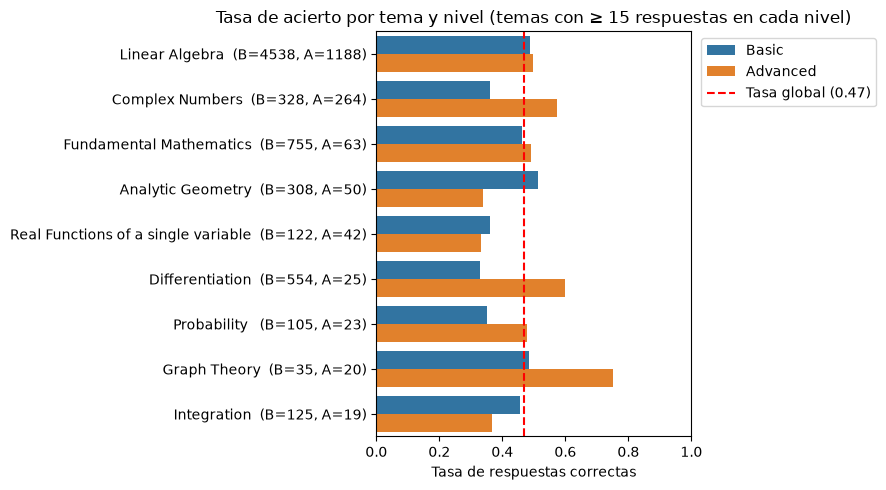

In [11]:
# ¿Las preguntas Advanced son más difíciles? Se compara el nivel dentro de cada tema.
# Cantidad de respuestas por tema y nivel (para saber qué comparaciones son confiables)
nivel_tema = pd.crosstab(df['Topic'], df['Question Level'])
display(nivel_tema)

# Solo se grafican los temas con al menos 15 respuestas en cada nivel
MIN_RESP = 15
temas = nivel_tema[(nivel_tema >= MIN_RESP).all(axis=1)].sort_values('Advanced', ascending=False).index

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=df[df['Topic'].isin(temas)], y='Topic', x=TARGET, order=temas,
            hue='Question Level', hue_order=['Basic', 'Advanced'], errorbar=None, ax=ax)
ax.set_yticks(range(len(temas)),
              [f"{t}  (B={nivel_tema.loc[t, 'Basic']}, A={nivel_tema.loc[t, 'Advanced']})" for t in temas])
ax.axvline(tasa_global, color='red', linestyle='--', label=f'Tasa global ({tasa_global:.2f})')
ax.set_xlim(0, 1)
ax.set_xlabel('Tasa de respuestas correctas')
ax.set_ylabel('')
ax.set_title(f'Tasa de acierto por tema y nivel (temas con ≥ {MIN_RESP} respuestas en cada nivel)')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Conclusiones:**
- **País:** en los países con más datos (Portugal, Lithuania, Italy, Ireland) la tasa de acierto ronda el 44–46 %. **Slovenia (69 %) no es un efecto del país:** sus 755 respuestas son de solo 3 estudiantes, y 727 (96 %) son de un único alumno (ID 1220). Además, Slovenia solo respondió *Linear Algebra*, y en ese mismo tema el resto de los países acierta 46 %. La diferencia refleja el nivel de un estudiante, que se captura mejor con `Student ID` (ver §5).
- Spain (1 estudiante, 28 respuestas), Russian Federation (1 estudiante, 107) y Romania (3 estudiantes, 60) tienen tasas poco confiables porque se apoyan en muy pocas respuestas y estudiantes. En general, `Student Country` aporta poca información propia.
- **Nivel:** que Advanced (50 %) supere a Basic (46 %) es contraintuitivo, y el patrón **no es consistente entre temas**. En *Complex Numbers* y *Differentiation* las Advanced se aciertan más, y en *Analytic Geometry* e *Integration* menos. Esto coincide con `descripcion.txt`: el nivel lo asigna el profesor que cargó la pregunta, así que no es una medida objetiva de dificultad. Se espera que sea una variable débil.
- **Tema y subtema:** sí muestran diferencias claras. Los temas de cálculo son los más difíciles (*Differentiation* 34 %, *Real Functions* 35 %, *Partial Differentiation* 32 %), y *Linear Systems*, *Eigenvalues* y *Elementary Geometry* superan el 56 %. Las tasas altas de *Set Theory* (64 %) y *Graph Theory* (58 %) se apoyan en pocas respuestas (42 y 55).
- *Linear Algebra* concentra el **60 % de las respuestas**, así que los modelos van a aprender sobre todo de ese tema.

## 4. Keywords

Cada celda tiene varias palabras clave separadas por coma.

**Corrección del separador de keywords.** La keyword `Addition, multiplication, and total probability rules` (preguntas de *Probability*) es una sola, pero tiene comas internas. Al separar por `,` se partía en tres keywords falsas: `Addition`, `multiplication` y `and total probability rules`. Los tres fragmentos no aparecen en ninguna otra fila, así que se reescribe la keyword sin comas antes de separar.

Para verificar que no queden otras keywords cortadas, se listan las que empiezan en minúscula, que es lo típico de un fragmento que viene después de una coma. Las únicas que quedan (`x-simple region (type II)` y `y-simple region (type I)`) son nombres reales de preguntas de integración doble.

In [12]:
# Keywords que contienen comas internas: se reescriben sin comas antes de separar por ','
KEYWORDS_CON_COMA = {
    'Addition, multiplication, and total probability rules':
        'Addition multiplication and total probability rules',
}
for original, corregida in KEYWORDS_CON_COMA.items():
    df['Keywords'] = df['Keywords'].str.replace(original, corregida, regex=False)

# Verificación: ya no aparecen los fragmentos sueltos
fragmentos = df['Keywords'].str.split(',').explode().str.strip()
assert not fragmentos.isin(['Addition', 'multiplication', 'and total probability rules']).any()

# Las únicas keywords que quedan en minúscula son legítimas (no vienen de un corte)
print('Keywords que empiezan en minúscula:', sorted(k for k in fragmentos.unique() if k[0].islower()))

Keywords que empiezan en minúscula: ['x-simple region (type II)', 'y-simple region (type I)']


In [13]:
keywords = df['Keywords'].str.split(',').explode().str.strip()
print('Keywords distintas:', keywords.nunique())
keywords.value_counts().head(20)

Keywords distintas: 191


Keywords
Span                                      1844
Subspace                                  1465
Linear combination                        1254
Basis                                     1112
Linear application                         824
Linearity                                  733
Range                                      713
Kernel                                     713
Dimension                                  615
Isomorphism                                587
Injective linear application               551
Matrix of a linear transformation          531
Simplify expressions                       496
Operations with complex numbers            461
Linear independence                        430
Linear dependence                          430
Inconsistent system                        420
Solution of linear system                  420
Undetermined solution of linear system     420
Consistent system                          420
Name: count, dtype: int64

**Conclusiones:**
- Con el separador corregido hay **191 keywords distintas**. Cada respuesta tiene en promedio 3 keywords (entre 1 y 13).
- La distribución está muy concentrada. Las más frecuentes son de *Linear Algebra* (Span, Subspace, Linear combination, Basis), algo esperable porque ese tema concentra el 60 % de las respuestas. En el otro extremo, 66 keywords aparecen menos de 30 veces y 30 aparecen menos de 10.
- Cada pregunta (`Question ID`) tiene siempre el mismo conjunto de keywords, así que las keywords describen a la pregunta con más detalle que `Topic` y `Subtopic`.
- El multi-hot genera 191 columnas binarias muy dispersas. Son candidatas a **selección de características** (Clase 5) si afectan el desempeño de los modelos. Se evalúa en el notebook 02.

## 5. Identificadores (`Student ID`, `Question ID`)

¿Cuántas respuestas hay por estudiante y por pregunta?

In [14]:
print(df['Student ID'].value_counts().describe())
print(df['Question ID'].value_counts().describe())

count    372.00000
mean      25.66129
std       48.48195
min        1.00000
25%        7.00000
50%       14.00000
75%       29.00000
max      727.00000
Name: count, dtype: float64
count    833.000000
mean      11.459784
std       18.431686
min        1.000000
25%        2.000000
50%        5.000000
75%       11.000000
max      103.000000
Name: count, dtype: float64


### 5.1 Outliers en la cantidad de respuestas

La media de respuestas por estudiante (25,7) casi duplica a la mediana (14), y el máximo es 727, así que la distribución tiene una cola larga a la derecha. Los outliers se identifican con el criterio del diagrama de cajas: valores mayores a Q3 + 1,5·IQR. Se hace el mismo análisis para las preguntas.

In [15]:
resp_est = df['Student ID'].value_counts()
resp_preg = df['Question ID'].value_counts()

# Outliers por el criterio del diagrama de cajas
q1, q3 = resp_est.quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
outliers = resp_est[resp_est > limite]
print(f'Límite superior (Q3 + 1,5·IQR): {limite:.0f} respuestas')
print(f'Estudiantes outliers: {len(outliers)} de {len(resp_est)}, '
      f'que suman {outliers.sum()} respuestas ({outliers.sum() / len(df):.1%} del dataset)')
print(f'El estudiante {resp_est.index[0]} aporta {resp_est.iloc[0]} respuestas ({resp_est.iloc[0] / len(df):.1%})')
print(f'Estudiantes con 5 respuestas o menos: {(resp_est <= 5).sum()}')
print(f'Preguntas con una sola respuesta: {(resp_preg == 1).sum()} de {len(resp_preg)}; '
      f'con menos de 5: {(resp_preg < 5).sum()} ({(resp_preg < 5).mean():.0%})')

# Los 10 estudiantes con más respuestas
top_est = (df.groupby('Student ID')
             .agg(respuestas=(TARGET, 'size'), tasa_acierto=(TARGET, 'mean'), pais=('Student Country', 'first'))
             .sort_values('respuestas', ascending=False)
             .head(10))
display(top_est.round(3))

Límite superior (Q3 + 1,5·IQR): 62 respuestas
Estudiantes outliers: 34 de 372, que suman 4104 respuestas (43.0% del dataset)
El estudiante 1220 aporta 727 respuestas (7.6%)
Estudiantes con 5 respuestas o menos: 63
Preguntas con una sola respuesta: 142 de 833; con menos de 5: 372 (45%)


,respuestas,tasa_acierto,pais
Student ID,,,
1220,727,0.685,Slovenia
91,321,0.636,Lithuania
168,221,0.403,Portugal
955,160,0.219,Lithuania
913,142,0.606,Ireland
37,140,0.621,Portugal
986,131,0.710,Portugal
175,125,0.472,Italy
1023,125,0.592,Lithuania


### 5.2 Nivel de acierto por estudiante

Para justificar que se conserva `Student ID`, hay que mostrar que los estudiantes difieren en su tasa de acierto y ver qué tan confiable es esa tasa según cuántas respuestas tiene cada uno.

In [16]:
por_est = df.groupby('Student ID')[TARGET].agg(tasa='mean', respuestas='size')

print(por_est['tasa'].describe().round(3), '\n')

# Dispersión de la tasa según cuántas respuestas tiene el estudiante
tramos = pd.cut(por_est['respuestas'], [0, 5, 20, 50, por_est['respuestas'].max()],
                labels=['1-5', '6-20', '21-50', 'más de 50'])
display(por_est.groupby(tramos, observed=True)['tasa'].agg(['count', 'mean', 'std']).round(3))

extremos = por_est['tasa'].isin([0, 1])
print(f'Estudiantes con tasa 0 o 1: {extremos.sum()}, '
      f'de los cuales {(extremos & (por_est["respuestas"] <= 3)).sum()} tienen 3 respuestas o menos')

count    372.000
mean       0.450
std        0.274
min        0.000
25%        0.240
50%        0.435
75%        0.643
max        1.000
Name: tasa, dtype: float64 



,count,mean,std
respuestas,,,
1-5,63,0.501,0.392
6-20,174,0.444,0.265
21-50,89,0.429,0.214
más de 50,46,0.448,0.210


Estudiantes con tasa 0 o 1: 56, de los cuales 33 tienen 3 respuestas o menos


**Conclusiones:**
- `Student ID` y `Question ID` son identificadores nominales: su valor numérico no significa nada (el estudiante 647 no es "mayor" que el 41), así que **no se usan como número**.
- **Outliers en cantidad de respuestas:** 34 de los 372 estudiantes superan el límite del diagrama de cajas (62 respuestas) y juntos aportan el **43 % del dataset**. El estudiante 1220 (Slovenia) aporta él solo 727 respuestas (7,6 %). No son errores de carga, sino alumnos que usaron mucho la plataforma, así que **se conservan**. Hay que tener en cuenta que los modelos van a aprender más de estos estudiantes que del resto.
- **`Student ID` se conserva** porque los estudiantes difieren mucho entre sí: la tasa de acierto va de 0 a 1, con desvío estándar 0,27 y la mitad central entre 0,24 y 0,64. La diferencia no es solo ruido: entre los estudiantes con más de 50 respuestas, cuya tasa es confiable, el desvío sigue siendo 0,21. Ninguna otra variable describe esto, y el país lo hace mal (ver §3.1).
  - Se codifica con **target encoding** (tasa de acierto histórica del estudiante) en el notebook 02, **dentro de cada fold** del cross-validation. Si se calculara con todo el dataset, el historial incluiría la respuesta que se quiere predecir (*data leakage*). Para un estudiante nuevo se usa el promedio general.
  - La tasa es poco confiable en los estudiantes con pocas respuestas: entre los que tienen de 1 a 5, el desvío es 0,39, y 33 de los 56 estudiantes con tasa 0 o 1 tienen 3 respuestas o menos. Por eso conviene aplicar el encoding con **suavizado**, es decir, mezclar la tasa del estudiante con la media global según cuántas respuestas tenga.
- **`Question ID` se descarta**. La mediana es de 5 respuestas por pregunta, 142 preguntas tienen una sola respuesta y el 45 % tiene menos de 5, así que una tasa por pregunta sería muy ruidosa. Además, la pregunta ya está descrita por `Question Level`, `Topic`, `Subtopic` y `Keywords` (cada pregunta tiene un conjunto fijo de keywords, ver §4).

### 5.3 ¿El nivel del estudiante depende del tema y del nivel de la pregunta?

El target encoding de `Student ID` resume a cada estudiante en una sola tasa de acierto. Pero a un mismo estudiante le puede ir bien en un tema y mal en otro, o distinto en preguntas básicas y avanzadas. Para ver si conviene una variable más específica, se calcula la tasa de acierto de cada combinación **estudiante × tema × nivel**.

In [17]:
# Tasa de acierto de cada combinación estudiante × tema × nivel
combo = df.groupby(['Student ID', 'Topic', 'Question Level'])[TARGET].agg(tasa='mean', respuestas='size')
print('Combinaciones estudiante × tema × nivel:', len(combo))
print(combo['respuestas'].describe().round(1), '\n')

# Estudiantes con al menos 2 combinaciones confiables (5 respuestas o más en cada una)
confiables = combo[combo['respuestas'] >= 5].reset_index()
rango = confiables.groupby('Student ID')['tasa'].agg(['count', 'min', 'max'])
rango = rango[rango['count'] >= 2]
dif = rango['max'] - rango['min']

print(f'Estudiantes con 2 o más combinaciones confiables: {len(rango)} de {df["Student ID"].nunique()} '
      f'({df["Student ID"].isin(rango.index).mean():.0%} de las respuestas)')
print(f'Diferencia entre su mejor y su peor combinación: mediana {dif.median():.2f}; '
      f'el {(dif >= 0.3).mean():.0%} de esos estudiantes tiene una diferencia de 0,30 o más')

Combinaciones estudiante × tema × nivel: 657
count    657.0
mean      14.5
std       32.2
min        1.0
25%        7.0
50%        7.0
75%       14.0
max      727.0
Name: respuestas, dtype: float64 

Estudiantes con 2 o más combinaciones confiables: 132 de 372 (64% de las respuestas)
Diferencia entre su mejor y su peor combinación: mediana 0.29; el 45% de esos estudiantes tiene una diferencia de 0,30 o más


**Conclusiones:**
- Hay 657 combinaciones estudiante × tema × nivel, con una mediana de 7 respuestas cada una.
- Entre los 132 estudiantes que tienen al menos dos combinaciones con 5 respuestas o más (que aportan el 64 % de las respuestas), la diferencia entre la combinación en la que mejor les va y la peor tiene una **mediana de 0,29**, y el 45 % supera los 0,30. Es decir, **el nivel de un mismo estudiante cambia bastante según el tema y el nivel de la pregunta**, y una única tasa por estudiante pierde esa información.
- Por eso se crea la variable **`Est_Topic_Level`**, que combina las tres columnas. Igual que `Student ID`, se codifica con **target encoding dentro de cada fold** en el notebook 02, y se conservan las dos: `Student ID` describe al estudiante en general y `Est_Topic_Level` en cada tema y nivel. Cuando una combinación tiene pocas respuestas, el suavizado del encoding la acerca al promedio general, y la tasa general del estudiante sigue disponible como referencia.

## 6. Duplicados y consistencia

Hay filas idénticas. Revisamos si son errores o reintentos de un mismo estudiante sobre la misma pregunta.

In [18]:
print('Filas duplicadas:', df.duplicated().sum())

pares = df.groupby(['Student ID', 'Question ID'])[TARGET].agg(['count', 'nunique'])
print('Pares estudiante-pregunta:', len(pares))
print('Pares con más de un intento:', (pares['count'] > 1).sum())
print('Pares cuyo resultado cambió entre intentos:', (pares['nunique'] > 1).sum())

Filas duplicadas: 2083
Pares estudiante-pregunta: 6782
Pares con más de un intento: 1457
Pares cuyo resultado cambió entre intentos: 681


In [19]:
# Jerarquía Topic -> Subtopic y consistencia de Question Level
print('Topics por subtopic (máx):', df.groupby('Subtopic')['Topic'].nunique().max())
print('Preguntas con más de un nivel:', (df.groupby('Question ID')['Question Level'].nunique() > 1).sum())

Topics por subtopic (máx): 1
Preguntas con más de un nivel: 1


**Conclusiones:**
- Los duplicados **no son errores de carga**: son reintentos (en varios casos el resultado cambia entre intentos). **Se mantienen**, porque son respuestas reales del dataset original.
- Cada subtopic pertenece a un único topic (hay jerarquía). Igual **se usan ambas** variables.
- Solo una pregunta tiene dos niveles distintos. Es una inconsistencia menor del dataset y se deja como está.

## 7. Transformación de categóricas a numéricas (Tarea 1.a)

| Variable | Encoding | Justificación |
|---|---|---|
| `Student ID` | Se conserva sin transformar → **target encoding en el notebook 02**, dentro de cada fold | Captura el nivel del estudiante sin *data leakage* |
| Estudiante × Topic × Level | Nueva variable: se combinan las tres columnas en un texto (ej. `1220 / Linear Algebra / Basic`) → **target encoding en el notebook 02**, dentro de cada fold | Captura el nivel del estudiante en cada tema y nivel de pregunta (ver §5.3) |
| `Question ID` | Se descarta | Pocas respuestas por pregunta; ya la describen las otras variables |
| `Question Level` | Binaria (Basic = 0, Advanced = 1) | Solo 2 valores |
| `Student Country` | One-hot | Nominal, sin orden |
| `Topic` | One-hot | Nominal, sin orden |
| `Subtopic` | One-hot | Nominal, sin orden |
| `Keywords` | Multi-hot (una columna 0/1 por keyword) | Cada respuesta tiene varias keywords |

In [20]:
# Student ID se conserva: el target encoding se aplica en el notebook 02, dentro de cada fold
df_proc = df.drop(columns=['Question ID'])


# Nueva variable: estudiante × tema × nivel (texto). El target encoding se aplica en el notebook 02, dentro de cada fold
df_proc['Est_Topic_Level'] = (df['Student ID'].astype(str) + ' / ' + df['Topic'] + ' / ' + df['Question Level'])

# Binaria
df_proc['Question Level'] = (df_proc['Question Level'] == 'Advanced').astype(int)

# One-hot
df_proc = pd.get_dummies(df_proc, columns=['Student Country', 'Topic', 'Subtopic'],
                         prefix=['Country', 'Topic', 'Subtopic'], dtype=int)

# Multi-hot de keywords (se limpian los espacios alrededor de cada keyword)
kw = (df_proc.pop('Keywords').str.split(',')
      .apply(lambda l: ','.join(k.strip() for k in l))
      .str.get_dummies(sep=',')
      .add_prefix('KW_'))
df_proc = pd.concat([df_proc, kw], axis=1)

print(df_proc.shape)
df_proc.head()

(9546, 241)


,Student ID,Type of Answer,Question Level,Est_Topic_Level,Country_Ireland,Country_Italy,Country_Lithuania,Country_Portugal,Country_Romania,Country_Russian Federation,...,KW_Trigonometric rules,KW_Trigonometric substitution,KW_Unconstrained optimization,KW_Undetermined solution of linear system,KW_Union of sets,KW_Variance,KW_Venn diagram,KW_Volume of revolution,KW_x-simple region (type II),KW_y-simple region (type I)
0,647,0,0,647 / Statistics / Basic,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,41,1,0,41 / Statistics / Basic,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,340,1,0,340 / Statistics / Basic,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,641,0,0,641 / Statistics / Basic,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,669,1,0,669 / Statistics / Basic,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [21]:
# Verificaciones
assert len(df_proc) == len(df)
# La única columna no numérica es Est_Topic_Level (se codifica en el notebook 02)
assert list(df_proc.select_dtypes(exclude='number').columns) == ['Est_Topic_Level'], 'Quedaron columnas no numéricas'
assert kw.shape[1] == keywords.nunique()
print('Columnas: 1 target + 1 Student ID + 1 Est_Topic_Level + 1 level +', df['Student Country'].nunique(), 'países +',
      df['Topic'].nunique(), 'topics +', df['Subtopic'].nunique(), 'subtopics +', kw.shape[1], 'keywords')
assert df_proc.shape[1] == 241

Columnas: 1 target + 1 Student ID + 1 Est_Topic_Level + 1 level + 8 países + 14 topics + 24 subtopics + 191 keywords


In [22]:
df_proc.to_csv(DATOS_PROCESADOS / 'datos_procesados.csv', index=False)